# Pandas Performance Stats

The same style of problems re-done with pandas on DataFrames of simulated daily returns.

- **Dollar P&L** — vectorized per-symbol profit and cumulative P&L through time.
- **Annualized stats** — return, volatility, Sharpe, and hit rate per symbol.
- **Reversal signal** — cross-sectional signal (+1 worst performer, -1 best performer each day) built with DataFrame ranking.

_Problem prompts paraphrased; all code is my own._

In [1]:
import numpy as np 
import pandas as pd 

np.random.seed(5)
rets = np.random.normal(0.05/252,0.1/np.sqrt(252), (1000,5))
columns = ['A','B','C','D','E']
rets = pd.DataFrame(rets,columns = columns)

dollarpos = np.random.normal(1000,100, (1000,5))
dollarpos = pd.DataFrame(dollarpos,columns = columns).abs()

<Axes: title={'center': 'cumulative dollar profit in A through time'}>

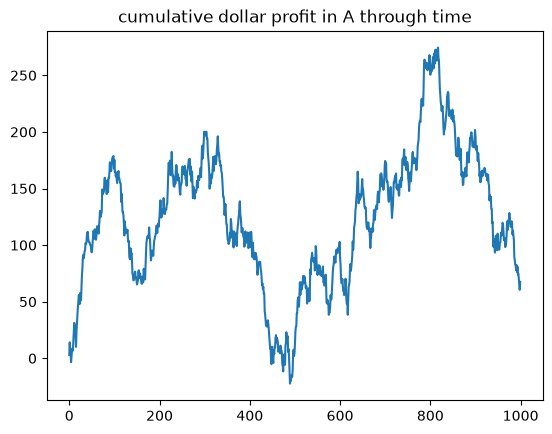

In [11]:
profit = dollarpos * rets
profit['A'].cumsum().plot(title='cumulative dollar profit in A through time')

In [12]:
import numpy as np 
import pandas as pd 

np.random.seed(5)
rets = np.random.normal(0.05/252,0.1/np.sqrt(252), (1000,5))
columns = ['A','B','C','D','E']
rets = pd.DataFrame(rets,columns = columns)

<Axes: title={'center': 'sharpe ratios in ascending order'}>

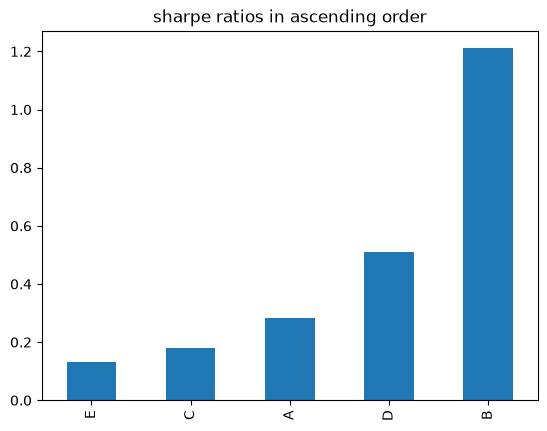

In [39]:
def compute_stats(rets):
    stats = {}
    stats['avg'] = rets.mean() * 252
    stats['vol'] = rets.std() * np.sqrt(252)
    stats['sharpe'] =  stats['avg'] / stats['vol']
    stats['hit_rate'] = rets[rets>0].count() / rets.count()
    return pd.DataFrame(stats)
stats = compute_stats(rets)
plot_value = stats['sharpe'].sort_values()
plot_value.plot(title='sharpe ratios in ascending order', kind='bar')

In [28]:
import numpy as np 
import pandas as pd 

np.random.seed(5)
rets = np.random.normal(0.05/252,0.1/np.sqrt(252), (1000,5))
columns = ['A','B','C','D','E']
rets = pd.DataFrame(rets,columns = columns)

       A    B    C    D    E
0    0.0  1.0 -1.0  0.0  0.0
1   -1.0  1.0  0.0  0.0  0.0
2    0.0  0.0  0.0 -1.0  1.0
3    0.0  0.0 -1.0  1.0  0.0
4    1.0  0.0  0.0  0.0 -1.0
..   ...  ...  ...  ...  ...
995  0.0  0.0 -1.0  1.0  0.0
996  0.0  0.0 -1.0  0.0  1.0
997  1.0  0.0  0.0  0.0 -1.0
998  0.0  0.0  1.0 -1.0  0.0
999 -1.0  0.0  0.0  1.0  0.0

[1000 rows x 5 columns]


<Axes: title={'center': 'value of signal through time for "A"'}>

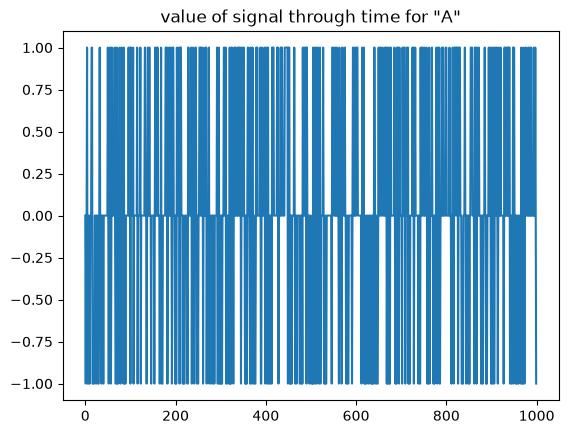

In [40]:
def reversal_signal(rets):
    rets_rank = rets.rank(axis=1)
    rets_rank[rets_rank==5] = -1
    rets_rank[rets_rank>1] = 0
    return rets_rank
signal = reversal_signal(rets)
print(signal)
signal['A'].plot(title='value of signal through time for "A"')